# Crop Recommendation - Complete Machine Learning Benchmark
### Train + Validation + Test + Model Comparison

This notebook follows the same **Block-wise format** as your uploaded example.

Workflow:
1. Exploratory Data Analysis & Descriptive Statistics
2. Data Preprocessing & Stratified Train/Validation/Test Split
3. Model Definition & Pipeline Setup (10 Classifiers)
4. Validation Comparison & Model Selection
5. Full Development Retraining & Final Test Evaluation
6. Confusion Matrix, Classification Report & Feature Importance
7. Automated Export to CSV & Excel Reports

**Important for this particular CSV:** It contains 2,200 original rows and 7,810 SMOTE-generated rows. The notebook uses only the 2,200 original rows for splitting and independent evaluation. The `data_origin` column is never used as a model feature. This avoids evaluating on synthetic rows derived from the original dataset.

## Block 1: Import Libraries and Configure Environment

In [1]:
import warnings
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import joblib

from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
OUTPUT_DIR = Path("Crop_ML_Benchmark_Results")
OUTPUT_DIR.mkdir(exist_ok=True)

print("Libraries imported successfully.")

Libraries imported successfully.


## Block 2: Load Dataset

In [11]:
# Keep the CSV file in the same folder as this notebook.
DATA_PATH = "Crop_Recommendation_10010_SMOTE_Augmented.csv"

df = pd.read_csv(DATA_PATH)
print("Dataset loaded successfully!")
print("Total records:", len(df))
print("Total columns:", len(df.columns))

Dataset loaded successfully!
Total records: 10010
Total columns: 9


## Block 3: Basic Dataset Information

In [12]:
print("=" * 60)
print("DATASET INFORMATION")
print("=" * 60)

print("\\nDataset Shape:")
print(df.shape)

print("\\nFirst 5 Rows:")
display(df.head())

print("\\nColumn Names:")
print(df.columns.tolist())

print("\\nDataset Information:")
df.info()

print("\\nMissing Values:")
display(df.isnull().sum())

print("\\nDuplicate Rows:")
print(df.duplicated().sum())

print("\\nData Origin Counts:")
display(df["data_origin"].value_counts())

DATASET INFORMATION
\nDataset Shape:
(10010, 9)
\nFirst 5 Rows:


,N,P,K,temperature,humidity,ph,rainfall,label,data_origin
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice,original
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice,original
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice,original
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice,original
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice,original


\nColumn Names:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label', 'data_origin']
\nDataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10010 entries, 0 to 10009
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            10010 non-null  int64  
 1   P            10010 non-null  int64  
 2   K            10010 non-null  int64  
 3   temperature  10010 non-null  float64
 4   humidity     10010 non-null  float64
 5   ph           10010 non-null  float64
 6   rainfall     10010 non-null  float64
 7   label        10010 non-null  object 
 8   data_origin  10010 non-null  object 
dtypes: float64(4), int64(3), object(2)
memory usage: 704.0+ KB
\nMissing Values:


N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
data_origin    0
dtype: int64

\nDuplicate Rows:
0
\nData Origin Counts:


data_origin
synthetic_SMOTE    7810
original           2200
Name: count, dtype: int64

## Block 4: Descriptive Statistics

In [13]:
print("=" * 60)
print("DESCRIPTIVE STATISTICS")
print("=" * 60)
display(df.describe(include="all").T)

DESCRIPTIVE STATISTICS


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
N,10010.0,NaN,NaN,NaN,50.364535,36.717613,0.0,21.0,36.0,84.0,140.0
P,10010.0,NaN,NaN,NaN,53.045055,32.912781,5.0,27.0,51.0,67.0,145.0
K,10010.0,NaN,NaN,NaN,47.798202,50.613667,5.0,20.0,31.0,48.0,205.0
temperature,10010.0,NaN,NaN,NaN,25.628131,4.922332,8.825675,22.748119,25.623092,28.49596,43.675493
humidity,10010.0,NaN,NaN,NaN,71.458005,22.170452,14.25804,60.289761,80.579527,89.995609,99.981876
ph,10010.0,NaN,NaN,NaN,6.463247,0.712443,3.504752,5.986919,6.434662,6.881412,9.935091
rainfall,10010.0,NaN,NaN,NaN,103.513728,54.922566,20.211267,64.730215,94.871892,124.166785,298.560117
label,10010,22,rice,455,NaN,NaN,NaN,NaN,NaN,NaN,NaN
data_origin,10010,2,synthetic_SMOTE,7810,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Block 5: Target Variable Distribution

TARGET DISTRIBUTION
label
apple          455
banana         455
blackgram      455
chickpea       455
coconut        455
coffee         455
cotton         455
grapes         455
jute           455
kidneybeans    455
lentil         455
maize          455
mango          455
mothbeans      455
mungbean       455
muskmelon      455
orange         455
papaya         455
pigeonpeas     455
pomegranate    455
rice           455
watermelon     455
Name: count, dtype: int64


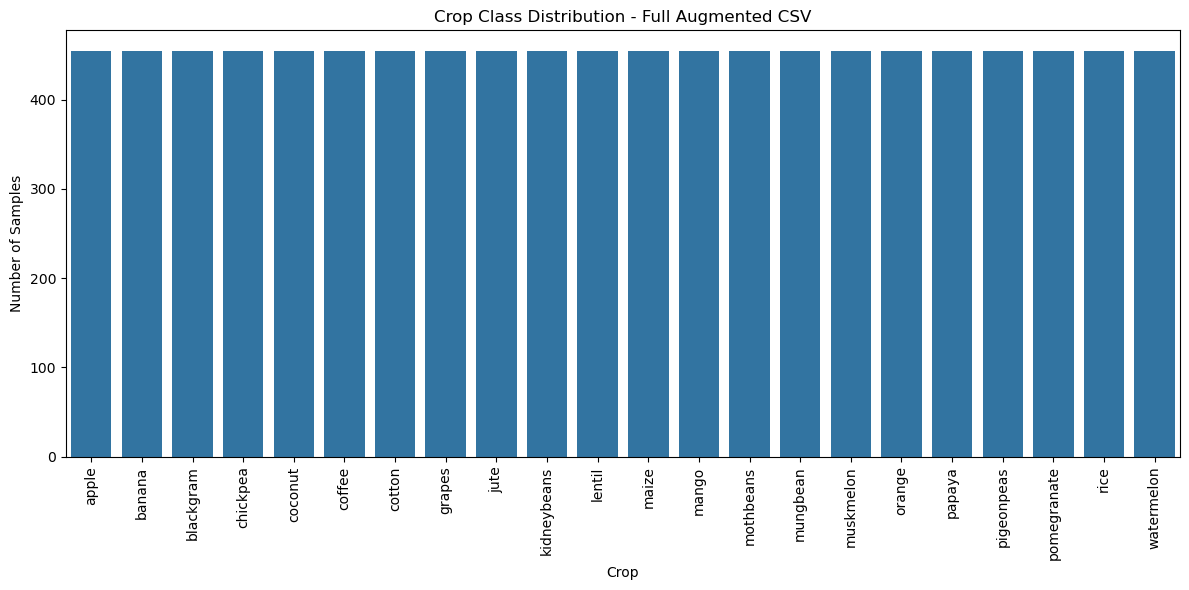

In [14]:
print("=" * 60)
print("TARGET DISTRIBUTION")
print("=" * 60)

print(df["label"].value_counts().sort_index())

plt.figure(figsize=(12, 6))
sns.countplot(data=df, x="label", order=sorted(df["label"].unique()))
plt.title("Crop Class Distribution - Full Augmented CSV")
plt.xlabel("Crop")
plt.ylabel("Number of Samples")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

## Block 6: Separate Original and Synthetic Records

In [15]:
# Keep only genuine source observations for independent train/validation/test evaluation.
# SMOTE-generated rows are retained in the CSV for transparency, but not used in the split.
original_df = df[
    df["data_origin"].astype(str).str.lower().eq("original")
].copy()

synthetic_count = (
    df["data_origin"].astype(str).str.lower().eq("synthetic_smote").sum()
)

print("Original records:", len(original_df))
print("SMOTE-generated records excluded from evaluation:", synthetic_count)

if original_df.empty:
    raise ValueError("No rows with data_origin='original' were found.")

original_df = original_df.dropna(
    subset=["N", "P", "K", "temperature", "humidity", "ph", "rainfall", "label"]
)
original_df = original_df.drop_duplicates(
    subset=["N", "P", "K", "temperature", "humidity", "ph", "rainfall", "label"]
).reset_index(drop=True)

print("Usable original records after cleaning:", len(original_df))

Original records: 2200
SMOTE-generated records excluded from evaluation: 7810
Usable original records after cleaning: 2200


## Block 7: Separate Features and Target

In [16]:
feature_columns = [
    "N", "P", "K", "temperature", "humidity", "ph", "rainfall"
]

X = original_df[feature_columns].astype(float)
y_original = original_df["label"].astype(str)

print("Features matrix shape:", X.shape)
print("Target vector shape:", y_original.shape)
print("Feature names:", feature_columns)

Features matrix shape: (2200, 7)
Target vector shape: (2200,)
Feature names: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']


## Block 8: Encode Target Labels

In [17]:
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_original)

print("Encoded Classes:")
print(label_encoder.classes_)
print("Number of crop classes:", len(label_encoder.classes_))

Encoded Classes:
['apple' 'banana' 'blackgram' 'chickpea' 'coconut' 'coffee' 'cotton'
 'grapes' 'jute' 'kidneybeans' 'lentil' 'maize' 'mango' 'mothbeans'
 'mungbean' 'muskmelon' 'orange' 'papaya' 'pigeonpeas' 'pomegranate'
 'rice' 'watermelon']
Number of crop classes: 22


## Block 9: Feature Information and Correlation Matrix

FEATURE INFORMATION
Feature Names: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
Number of Features: 7


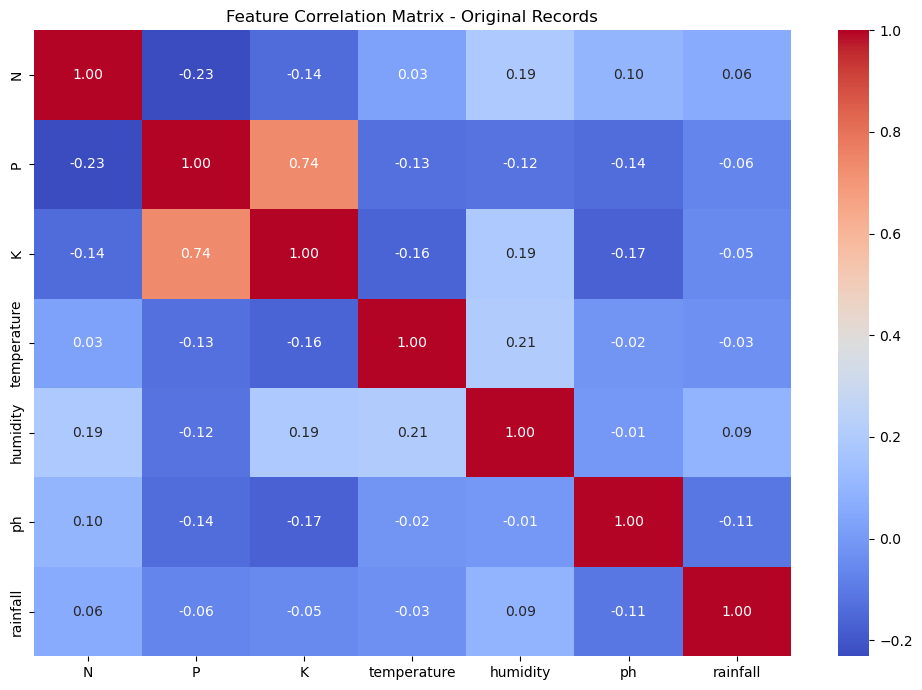

In [18]:
print("=" * 60)
print("FEATURE INFORMATION")
print("=" * 60)
print("Feature Names:", X.columns.tolist())
print("Number of Features:", X.shape[1])

plt.figure(figsize=(10, 7))
sns.heatmap(X.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Matrix - Original Records")
plt.tight_layout()
plt.show()

## Block 10: Stratified Train / Validation / Test Split
- 70% Training
- 15% Validation
- 15% Testing

In [19]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    stratify=y,
    random_state=RANDOM_STATE
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=RANDOM_STATE
)

print("=" * 60)
print("DATA SPLIT")
print("=" * 60)
print("Training Samples   :", len(X_train))
print("Validation Samples :", len(X_val))
print("Testing Samples    :", len(X_test))

split_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Testing"],
    "Samples": [len(X_train), len(X_val), len(X_test)]
})
display(split_summary)

DATA SPLIT
Training Samples   : 1540
Validation Samples : 330
Testing Samples    : 330


,Dataset,Samples
0,Training,1540
1,Validation,330
2,Testing,330


## Block 11: Define Machine Learning Models (10 Classifiers)

In [20]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=3000, C=1.0, random_state=RANDOM_STATE))
    ]),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(C=1.0, kernel="rbf"))
    ]),

    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),

    "Random Forest": RandomForestClassifier(
        n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),

    "AdaBoost": AdaBoostClassifier(n_estimators=200, random_state=RANDOM_STATE),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1
    ),

    "Gaussian Naive Bayes": Pipeline([
        ("scaler", StandardScaler()),
        ("model", GaussianNB())
    ]),

    "MLP Neural Network": Pipeline([
        ("scaler", StandardScaler()),
        ("model", MLPClassifier(
            hidden_layer_sizes=(100,),
            max_iter=1000,
            early_stopping=False,
            random_state=RANDOM_STATE
        ))
    ])
}

print(f"Configured {len(models)} classification models.")
for model_name in models:
    print("-", model_name)

Configured 10 classification models.
- Logistic Regression
- KNN
- SVM
- Decision Tree
- Random Forest
- Gradient Boosting
- AdaBoost
- Extra Trees
- Gaussian Naive Bayes
- MLP Neural Network


## Block 12: Train All Models & Evaluate on Validation Set

In [21]:
validation_results = []
fitted_models = {}

print("=" * 60)
print("MODEL TRAINING & VALIDATION EVALUATION")
print("=" * 60)

for name, model in models.items():
    print("\\nTraining:", name)
    start_time = time.time()

    model.fit(X_train, y_train)
    elapsed_time = time.time() - start_time
    fitted_models[name] = model

    train_prediction = model.predict(X_train)
    val_prediction = model.predict(X_val)

    train_accuracy = accuracy_score(y_train, train_prediction)
    accuracy = accuracy_score(y_val, val_prediction)
    precision = precision_score(y_val, val_prediction, average="macro", zero_division=0)
    recall = recall_score(y_val, val_prediction, average="macro", zero_division=0)
    f1 = f1_score(y_val, val_prediction, average="macro", zero_division=0)

    validation_results.append([
        name, train_accuracy, accuracy, precision, recall, f1, elapsed_time
    ])

    print("Completed:", name)

print("\\nAll models trained.")

MODEL TRAINING & VALIDATION EVALUATION
\nTraining: Logistic Regression
Completed: Logistic Regression
\nTraining: KNN
Completed: KNN
\nTraining: SVM
Completed: SVM
\nTraining: Decision Tree
Completed: Decision Tree
\nTraining: Random Forest
Completed: Random Forest
\nTraining: Gradient Boosting
Completed: Gradient Boosting
\nTraining: AdaBoost
Completed: AdaBoost
\nTraining: Extra Trees
Completed: Extra Trees
\nTraining: Gaussian Naive Bayes
Completed: Gaussian Naive Bayes
\nTraining: MLP Neural Network
Completed: MLP Neural Network
\nAll models trained.


## Block 13: Validation Results Table

In [22]:
validation_df = pd.DataFrame(
    validation_results,
    columns=[
        "Model", "Train Accuracy", "Validation Accuracy",
        "Precision", "Recall", "F1 Score", "Training Time (sec)"
    ]
)

validation_df = validation_df.sort_values(
    by=["F1 Score", "Validation Accuracy"],
    ascending=False
).reset_index(drop=True)

display(validation_df.style.format({
    "Train Accuracy": "{:.2%}",
    "Validation Accuracy": "{:.2%}",
    "Precision": "{:.2%}",
    "Recall": "{:.2%}",
    "F1 Score": "{:.2%}",
    "Training Time (sec)": "{:.2f}"
}))

,Model,Train Accuracy,Validation Accuracy,Precision,Recall,F1 Score,Training Time (sec)
0,Extra Trees,100.00%,99.70%,99.72%,99.70%,99.70%,0.48
1,MLP Neural Network,99.81%,99.70%,99.72%,99.70%,99.70%,4.48
2,Gaussian Naive Bayes,99.55%,99.39%,99.43%,99.39%,99.39%,0.01
3,Random Forest,100.00%,99.09%,99.15%,99.09%,99.09%,0.72
4,SVM,98.18%,99.09%,99.18%,99.09%,99.09%,0.05
5,Gradient Boosting,100.00%,98.48%,98.59%,98.48%,98.48%,9.94
6,KNN,98.18%,98.48%,98.61%,98.48%,98.48%,0.01
7,Decision Tree,100.00%,97.58%,97.60%,97.58%,97.55%,0.01
8,Logistic Regression,97.47%,96.67%,96.80%,96.67%,96.65%,0.12
9,AdaBoost,27.53%,27.27%,17.77%,27.27%,19.94%,0.72


## Block 14: Validation Accuracy Comparison Graph

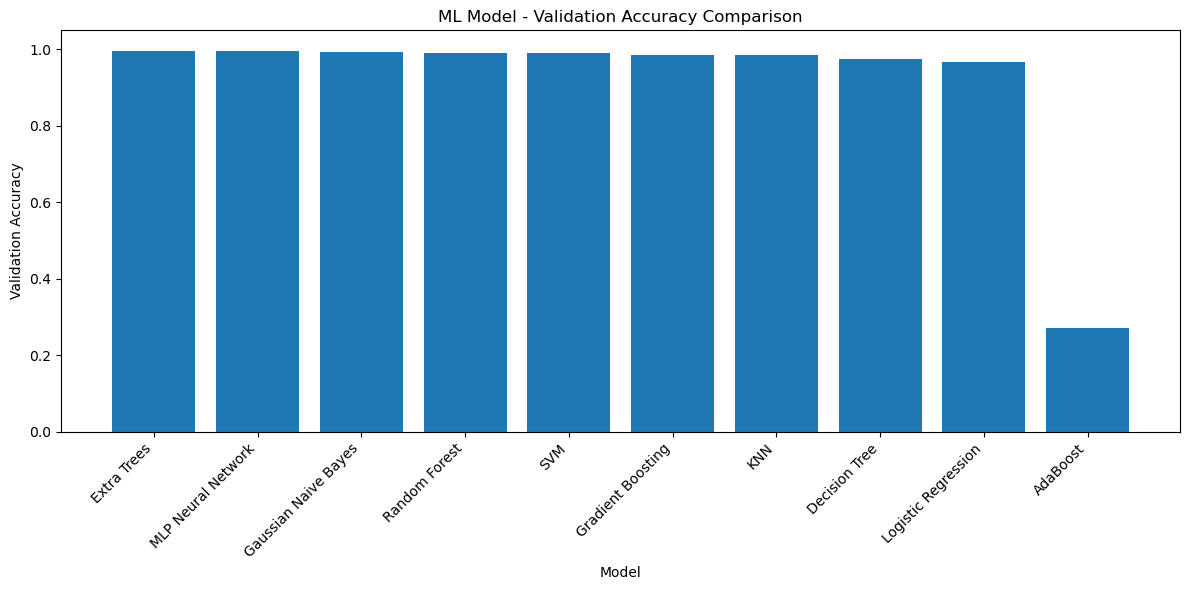

In [23]:
plt.figure(figsize=(12, 6))
plt.bar(validation_df["Model"], validation_df["Validation Accuracy"])
plt.title("ML Model - Validation Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Validation Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Block 15: Find Best Model Using Validation Macro F1

In [24]:
best_model_name = validation_df.iloc[0]["Model"]
best_validation_accuracy = validation_df.iloc[0]["Validation Accuracy"]
best_validation_f1 = validation_df.iloc[0]["F1 Score"]

print("=" * 60)
print("BEST MODEL SELECTION")
print("=" * 60)
print("Best Model:", best_model_name)
print(f"Validation Accuracy: {best_validation_accuracy * 100:.2f}%")
print(f"Validation Macro F1: {best_validation_f1 * 100:.2f}%")

BEST MODEL SELECTION
Best Model: Extra Trees
Validation Accuracy: 99.70%
Validation Macro F1: 99.70%


## Block 16: Combine Training & Validation Data for Final Retraining

In [25]:
X_development = pd.concat([X_train, X_val], axis=0)
y_development = np.concatenate([y_train, y_val])

print("Combined Development Set:", len(X_development), "samples")

Combined Development Set: 1870 samples


## Block 17: Initialize Final Model Architecture

In [26]:
from sklearn.base import clone

# Clone the best model configuration selected during validation.
final_model = clone(models[best_model_name])

print("Final Model Architecture:")
print(final_model)

Final Model Architecture:
ExtraTreesClassifier(n_estimators=300, n_jobs=-1, random_state=42)


## Block 18: Retrain Final Model on Full Development Set

In [27]:
print("Training final model on Train + Validation combined data...")
final_model.fit(X_development, y_development)
print("Training complete.")

Training final model on Train + Validation combined data...
Training complete.


## Block 19: Final Test Prediction & Metric Calculation

In [28]:
final_prediction = final_model.predict(X_test)

test_accuracy = accuracy_score(y_test, final_prediction)
test_precision = precision_score(y_test, final_prediction, average="macro", zero_division=0)
test_recall = recall_score(y_test, final_prediction, average="macro", zero_division=0)
test_f1 = f1_score(y_test, final_prediction, average="macro", zero_division=0)

## Block 20: Display Final Test Results

In [29]:
print("=" * 60)
print("FINAL TEST RESULT")
print("=" * 60)
print("Selected Model :", best_model_name)
print(f"Test Accuracy  : {test_accuracy * 100:.2f}%")
print(f"Test Precision : {test_precision * 100:.2f}%")
print(f"Test Recall    : {test_recall * 100:.2f}%")
print(f"Test F1 Score  : {test_f1 * 100:.2f}%")

FINAL TEST RESULT
Selected Model : Extra Trees
Test Accuracy  : 99.09%
Test Precision : 99.18%
Test Recall    : 99.09%
Test F1 Score  : 99.09%


## Block 21: Classification Report

In [30]:
print("=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)

print(classification_report(
    y_test,
    final_prediction,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

CLASSIFICATION REPORT
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        15
      banana       1.00      1.00      1.00        15
   blackgram       1.00      1.00      1.00        15
    chickpea       1.00      1.00      1.00        15
     coconut       1.00      1.00      1.00        15
      coffee       1.00      1.00      1.00        15
      cotton       1.00      1.00      1.00        15
      grapes       1.00      1.00      1.00        15
        jute       0.88      1.00      0.94        15
 kidneybeans       1.00      1.00      1.00        15
      lentil       1.00      0.93      0.97        15
       maize       1.00      1.00      1.00        15
       mango       1.00      1.00      1.00        15
   mothbeans       0.94      1.00      0.97        15
    mungbean       1.00      1.00      1.00        15
   muskmelon       1.00      1.00      1.00        15
      orange       1.00      1.00      1.00        15
     

## Block 22: Confusion Matrix Heatmap

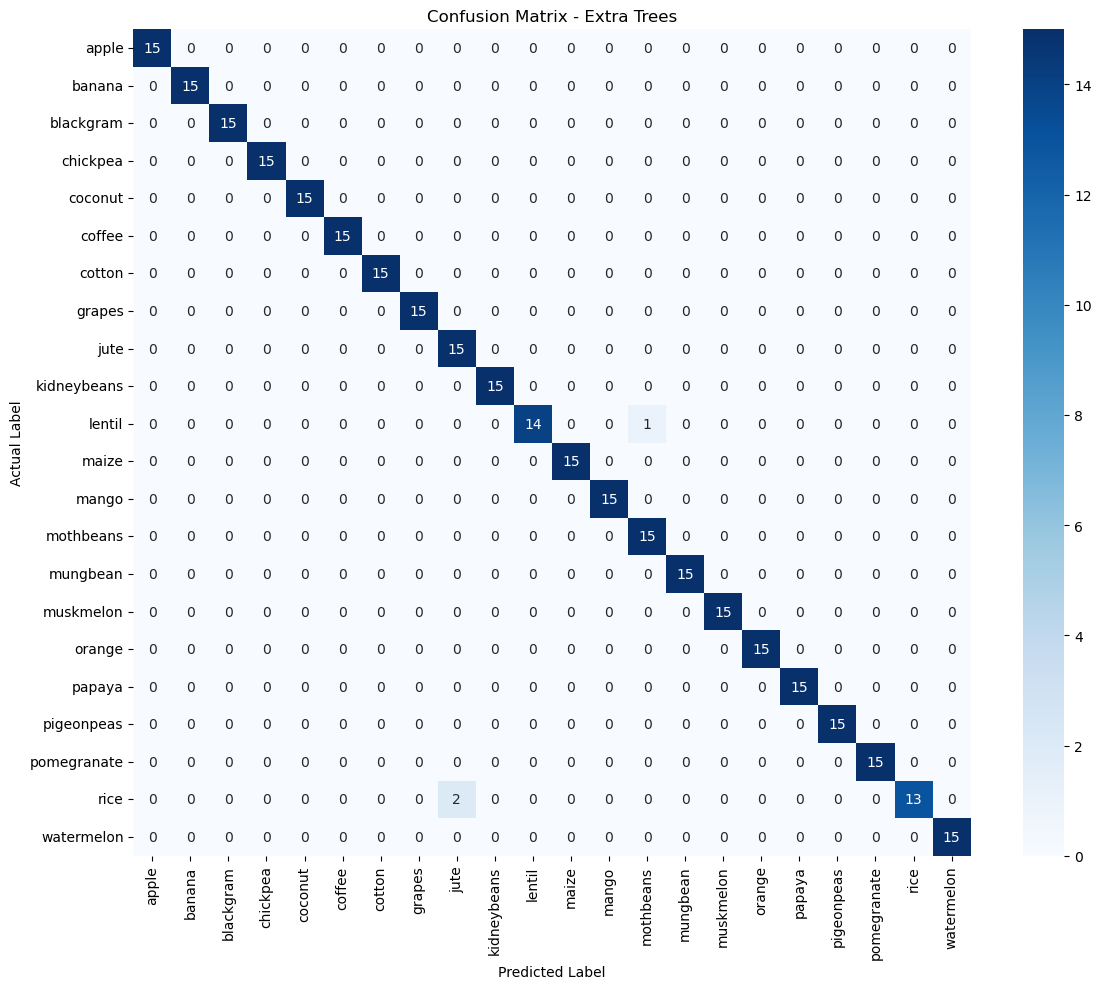

In [31]:
cm = confusion_matrix(
    y_test, final_prediction,
    labels=np.arange(len(label_encoder.classes_))
)

plt.figure(figsize=(12, 10))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Block 23: Feature Importance Analysis

,Feature,Importance,Importance Std
4,humidity,0.289826,0.018070
6,rainfall,0.211236,0.014371
2,K,0.177385,0.014551
0,N,0.144449,0.008722
1,P,0.113862,0.012364
3,temperature,0.004639,0.005587
5,ph,0.003337,0.003711


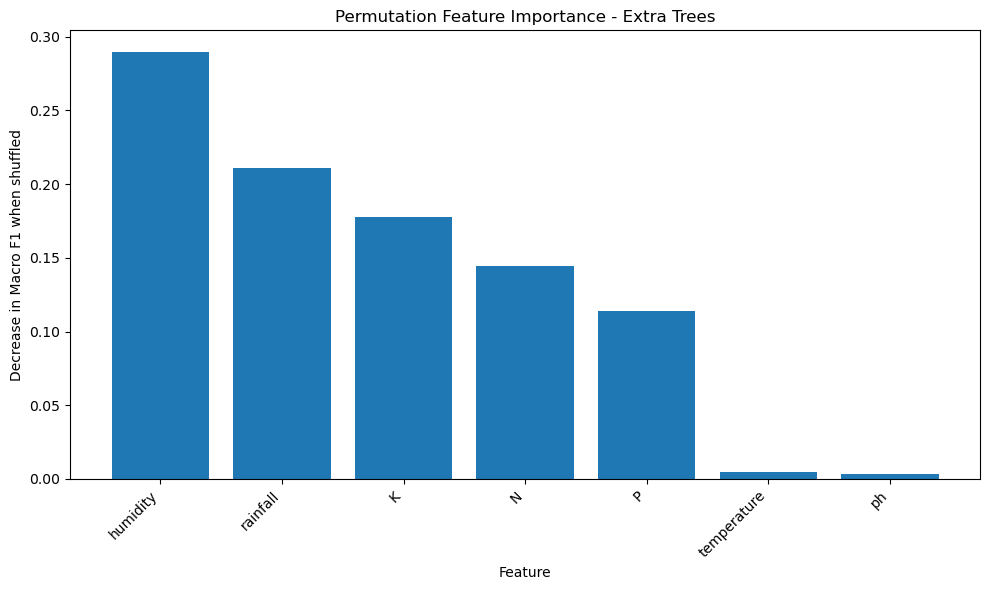

In [32]:
# Permutation importance works for all model types, including SVM and KNN.
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    final_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=RANDOM_STATE,
    scoring="f1_macro",
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": perm.importances_mean,
    "Importance Std": perm.importances_std
}).sort_values(by="Importance", ascending=False)

display(feature_importance)

plt.figure(figsize=(10, 6))
plt.bar(feature_importance["Feature"], feature_importance["Importance"])
plt.title(f"Permutation Feature Importance - {best_model_name}")
plt.xlabel("Feature")
plt.ylabel("Decrease in Macro F1 when shuffled")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Block 24: Test Performance of All Models

In [33]:
# Evaluate each model trained on the training split on the same untouched test set.
# These are comparison-only test scores; the selected final model above is the primary result.
test_results = []

for name, model in fitted_models.items():
    test_prediction = model.predict(X_test)

    accuracy = accuracy_score(y_test, test_prediction)
    precision = precision_score(y_test, test_prediction, average="macro", zero_division=0)
    recall = recall_score(y_test, test_prediction, average="macro", zero_division=0)
    f1 = f1_score(y_test, test_prediction, average="macro", zero_division=0)

    test_results.append([name, accuracy, precision, recall, f1])

test_df = pd.DataFrame(
    test_results,
    columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"]
).sort_values(by="F1 Score", ascending=False).reset_index(drop=True)

display(test_df.style.format({
    "Accuracy": "{:.2%}", "Precision": "{:.2%}",
    "Recall": "{:.2%}", "F1 Score": "{:.2%}"
}))

,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,100.00%,100.00%,100.00%,100.00%
1,Gradient Boosting,100.00%,100.00%,100.00%,100.00%
2,Extra Trees,99.39%,99.43%,99.39%,99.39%
3,Gaussian Naive Bayes,99.09%,99.18%,99.09%,99.09%
4,SVM,98.79%,98.90%,98.79%,98.78%
5,MLP Neural Network,98.48%,98.54%,98.48%,98.48%
6,Decision Tree,98.18%,98.29%,98.18%,98.18%
7,Logistic Regression,97.88%,97.95%,97.88%,97.87%
8,KNN,97.27%,97.54%,97.27%,97.24%
9,AdaBoost,27.88%,18.31%,27.88%,20.39%


## Block 25: Test Accuracy Comparison Graph

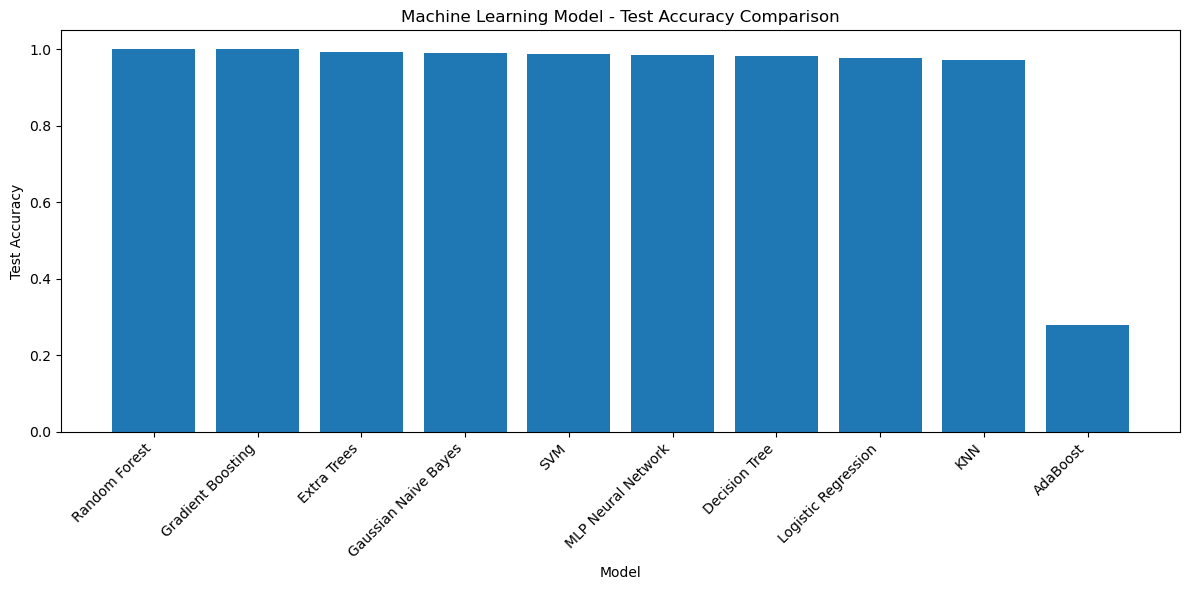

In [34]:
plt.figure(figsize=(12, 6))
plt.bar(test_df["Model"], test_df["Accuracy"])
plt.title("Machine Learning Model - Test Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Test Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Block 26: Final Results Summary DataFrame

In [35]:
final_results = pd.DataFrame({
    "Metric": [
        "Selected Model",
        "Validation Accuracy",
        "Validation Macro F1",
        "Final Test Accuracy",
        "Final Test Precision",
        "Final Test Recall",
        "Final Test F1 Score"
    ],
    "Value": [
        best_model_name,
        f"{best_validation_accuracy * 100:.2f}%",
        f"{best_validation_f1 * 100:.2f}%",
        f"{test_accuracy * 100:.2f}%",
        f"{test_precision * 100:.2f}%",
        f"{test_recall * 100:.2f}%",
        f"{test_f1 * 100:.2f}%"
    ]
})
display(final_results)

,Metric,Value
0,Selected Model,Extra Trees
1,Validation Accuracy,99.70%
2,Validation Macro F1,99.70%
3,Final Test Accuracy,99.09%
4,Final Test Precision,99.18%
5,Final Test Recall,99.09%
6,Final Test F1 Score,99.09%


## Block 27: Save Results to CSV Files

In [36]:
validation_df.to_csv(OUTPUT_DIR / "validation_model_comparison.csv", index=False)
test_df.to_csv(OUTPUT_DIR / "test_model_comparison.csv", index=False)
final_results.to_csv(OUTPUT_DIR / "final_model_results.csv", index=False)
feature_importance.to_csv(OUTPUT_DIR / "feature_importance.csv", index=False)
split_summary.to_csv(OUTPUT_DIR / "data_split_summary.csv", index=False)

print("All CSV reports saved in:", OUTPUT_DIR.resolve())

All CSV reports saved in: C:\Users\Pranav\Crop_ML_Benchmark_Results


## Block 28: Save Results to Excel Workbook

In [37]:
excel_path = OUTPUT_DIR / "Crop_ML_Benchmark_Results.xlsx"

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    validation_df.to_excel(writer, sheet_name="Validation Results", index=False)
    test_df.to_excel(writer, sheet_name="Test Results", index=False)
    final_results.to_excel(writer, sheet_name="Final Summary", index=False)
    feature_importance.to_excel(writer, sheet_name="Feature Importance", index=False)
    split_summary.to_excel(writer, sheet_name="Data Split", index=False)

print("Workbook saved successfully:", excel_path.resolve())

Workbook saved successfully: C:\Users\Pranav\Crop_ML_Benchmark_Results\Crop_ML_Benchmark_Results.xlsx


## Block 29: Save Final Model and Label Encoder

In [38]:
joblib.dump(final_model, OUTPUT_DIR / "best_crop_recommendation_model.joblib")
joblib.dump(label_encoder, OUTPUT_DIR / "crop_label_encoder.joblib")
print("Final model and label encoder saved successfully.")

Final model and label encoder saved successfully.


## Block 30: Final Project Conclusion

In [39]:
print("=" * 70)
print("FINAL PROJECT CONCLUSION")
print("=" * 70)

print(f'''
Dataset file:
{DATA_PATH}

Total rows in CSV:
{len(df)}

Original rows used for independent evaluation:
{len(original_df)}

Synthetic SMOTE rows excluded from evaluation:
{synthetic_count}

Number of input features:
{X.shape[1]}

Number of crop classes:
{len(label_encoder.classes_)}

Data split:
70% Training
15% Validation
15% Testing

Number of algorithms compared:
{len(models)}

Best Model:
{best_model_name}

Validation Accuracy:
{best_validation_accuracy * 100:.2f}%

Final Test Accuracy:
{test_accuracy * 100:.2f}%

Final Test Precision:
{test_precision * 100:.2f}%

Final Test Recall:
{test_recall * 100:.2f}%

Final Test F1 Score:
{test_f1 * 100:.2f}%

The best model was selected using validation macro-F1.
The final model was retrained on train + validation data
and evaluated on the untouched test set.
''')

print("=" * 70)
print("All output files are saved in:", OUTPUT_DIR.resolve())

FINAL PROJECT CONCLUSION

Dataset file:
Crop_Recommendation_10010_SMOTE_Augmented.csv

Total rows in CSV:
10010

Original rows used for independent evaluation:
2200

Synthetic SMOTE rows excluded from evaluation:
7810

Number of input features:
7

Number of crop classes:
22

Data split:
70% Training
15% Validation
15% Testing

Number of algorithms compared:
10

Best Model:
Extra Trees

Validation Accuracy:
99.70%

Final Test Accuracy:
99.09%

Final Test Precision:
99.18%

Final Test Recall:
99.09%

Final Test F1 Score:
99.09%

The best model was selected using validation macro-F1.
The final model was retrained on train + validation data
and evaluated on the untouched test set.

All output files are saved in: C:\Users\Pranav\Crop_ML_Benchmark_Results
